In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
import joblib

data = pd.read_csv("/content/student-mat.csv",sep=";")
data.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [ ]:
print(data.isnull().sum())

print("Any missing values? ->", data.isnull().values.any())

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64
Any missing values? -> False


In [ ]:

print("Duplicate rows:", data.duplicated().sum())

Duplicate rows: 0


In [ ]:
import numpy as np

numeric_cols = data.select_dtypes(include=np.number).columns

Q1 = data[numeric_cols].quantile(0.25)
Q3 = data[numeric_cols].quantile(0.75)
IQR = Q3 - Q1

outliers = ((data[numeric_cols] < (Q1 - 1.5 * IQR)) |
            (data[numeric_cols] > (Q3 + 1.5 * IQR)))

print("Outliers detected:\n", outliers.sum())

Outliers detected:
 age            1
Medu           0
Fedu           2
traveltime     8
studytime     27
failures      83
famrel        26
freetime      19
goout          0
Dalc          18
Walc           0
health         0
absences      15
G1             0
G2            13
G3             0
dtype: int64


In [ ]:
data = data[~((data[numeric_cols] < (Q1 - 1.5 * IQR)) |
              (data[numeric_cols] > (Q3 + 1.5 * IQR))).any(axis=1)]

print("Outliers removed.")

Outliers removed.


In [ ]:
print(data.columns)

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='object')


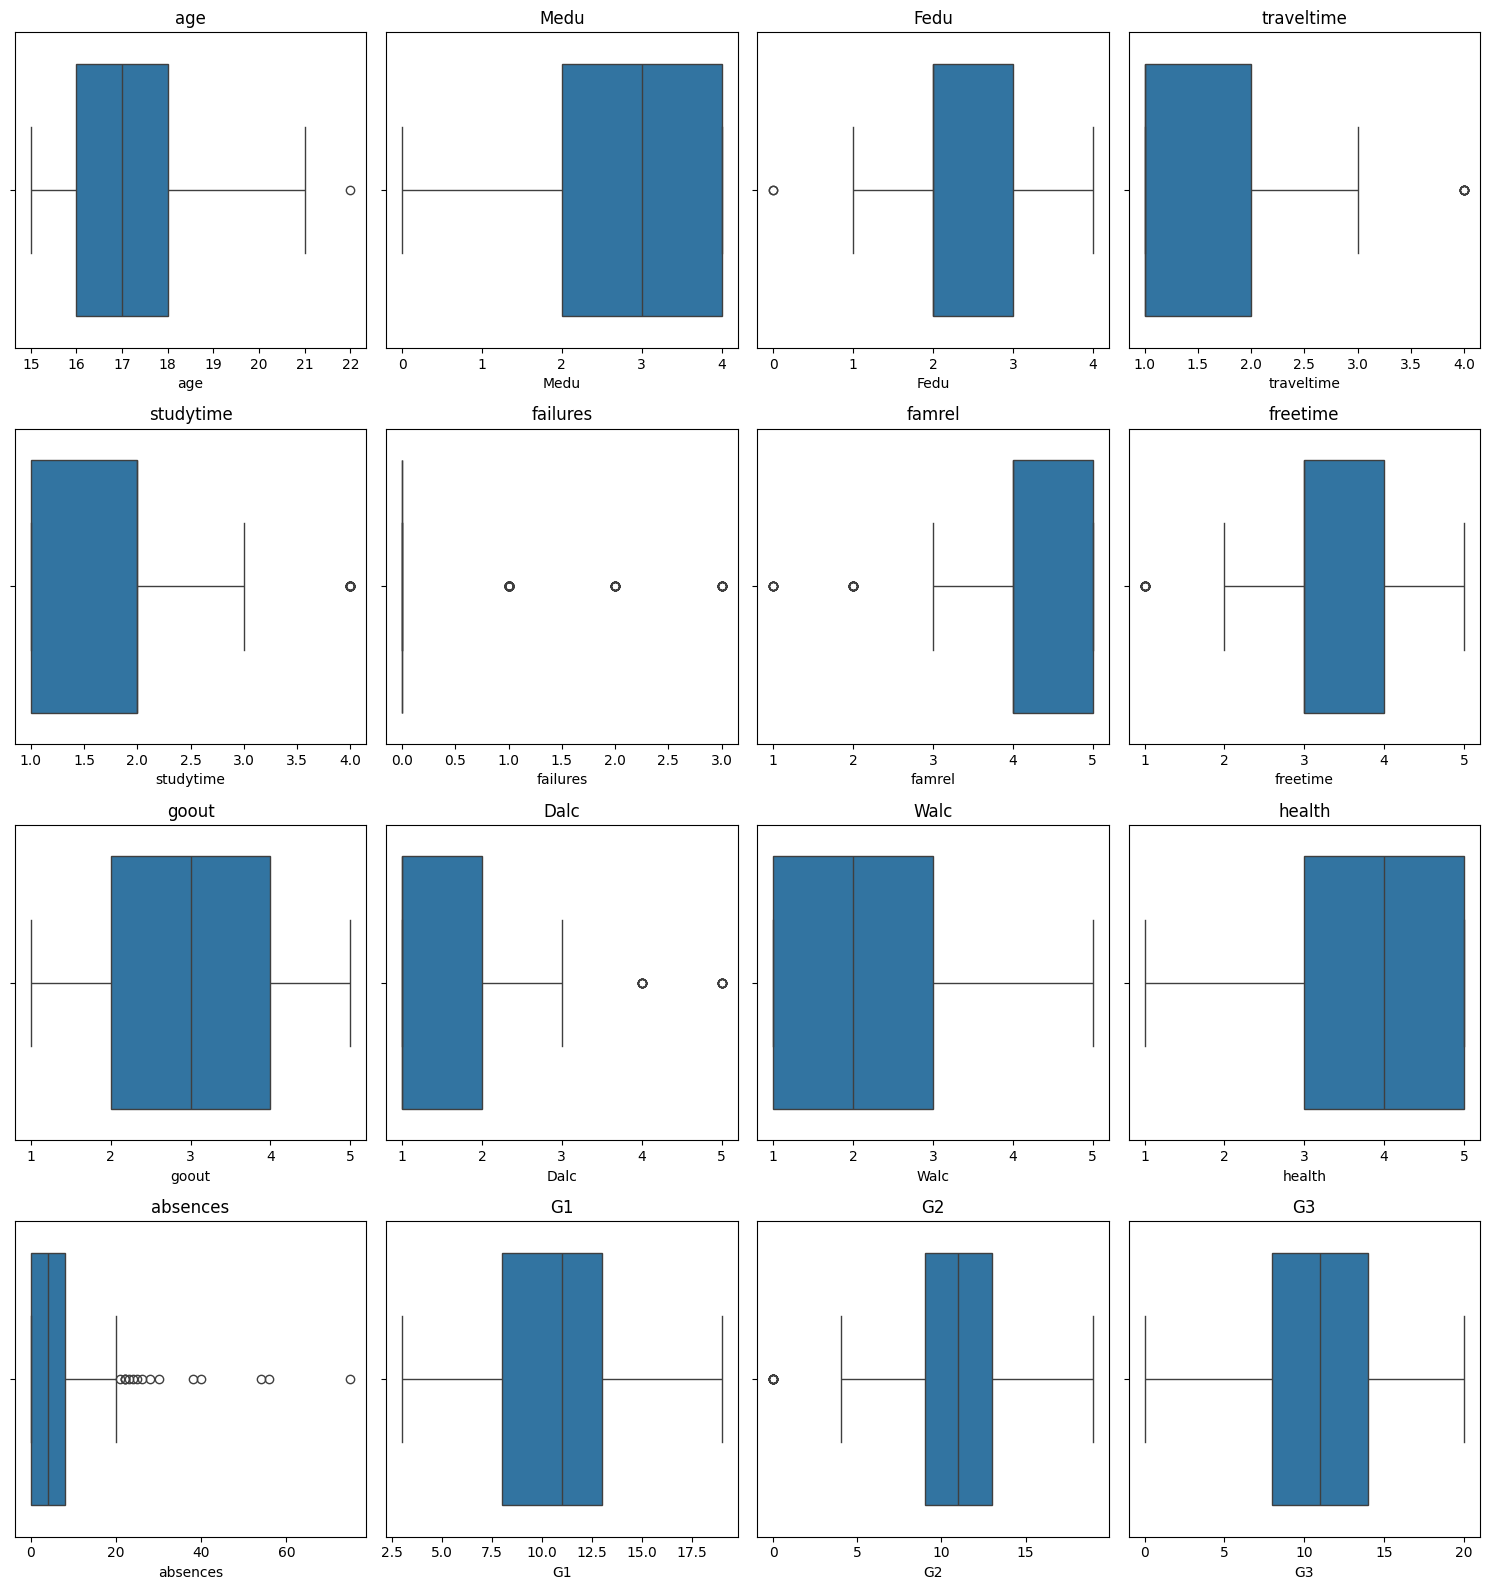

In [ ]:
import math
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

numeric_cols = data.select_dtypes(include=np.number).columns
num_cols = len(numeric_cols)

rows = math.ceil(num_cols / 4)

plt.figure(figsize=(15, rows * 4))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(rows, 4, i)
    sns.boxplot(x=data[col])
    plt.title(col)

plt.tight_layout()
plt.show()

Converted continuous grade into categories to make output more interpretable

In [ ]:
def categorize(grade):
    if grade >= 15:
        return "High"
    elif grade >= 10:
        return "Average"
    else:
        return "AtRisk"

data["performance"] = data["G3"].apply(categorize)

To see which features are strongly related to G3


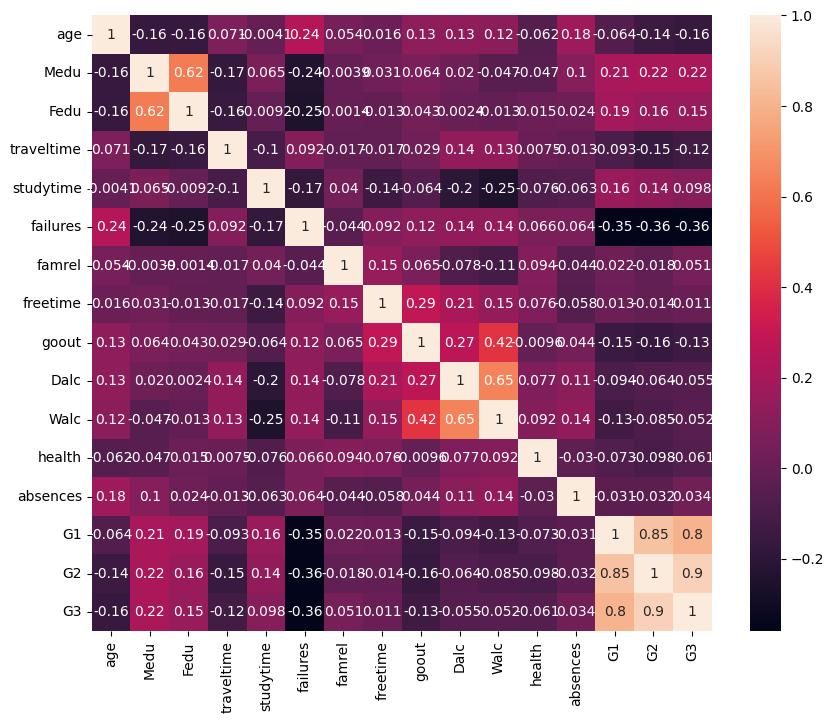

In [ ]:
numeric_data = data.select_dtypes(include=['int64'])

plt.figure(figsize=(10,8))
sns.heatmap(numeric_data.corr(), annot=True)
plt.show()

In [ ]:

le = LabelEncoder()
data["performance"] = le.fit_transform(data["performance"])

X = data[["studytime", "failures", "absences", "G1", "G2"]]
y = data["performance"]

model = RandomForestClassifier()
model.fit(X, y)

importance = model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
}).sort_values(by="Importance", ascending=False)

print(feature_importance)

     Feature  Importance
4         G2    0.574771
3         G1    0.247973
2   absences    0.089845
0  studytime    0.043948
1   failures    0.043464


Select Final Features

In [ ]:
X = data[["studytime", "failures", "absences", "G1", "G2"]]
y = data["performance"]

Split Data

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)

lr_accuracy = accuracy_score(y_test, y_pred_lr)
print("Logistic Regression Accuracy:", lr_accuracy)

Logistic Regression Accuracy: 0.851063829787234


In [ ]:
Decision Tree

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Train model
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# Predict
y_pred_dt = dt_model.predict(X_test)

# Accuracy
dt_accuracy = accuracy_score(y_test, y_pred_dt)
print("Decision Tree Accuracy:", dt_accuracy)

Decision Tree Accuracy: 0.8085106382978723


Train Model

RandomForestClassifier(n_estimators=200, random_state=42)

Evaluate Accuracy(50-2000)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
model = RandomForestClassifier(n_estimators=200, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy:", model.score(X_test, y_test))
print(classification_report(y_test, y_pred))

Accuracy: 0.8734177215189873
              precision    recall  f1-score   support

           0       0.83      0.93      0.88        27
           1       0.84      0.84      0.84        32
           2       1.00      0.85      0.92        20

    accuracy                           0.87        79
   macro avg       0.89      0.87      0.88        79
weighted avg       0.88      0.87      0.87        79



In [ ]:
model = RandomForestClassifier(n_estimators=20, random_state=42)
model.fit(X_train, y_train)

RandomForestClassifier(n_estimators=20, random_state=42)

In [ ]:
y_pred = model.predict(X_test)

print("Accuracy:", model.score(X_test, y_test))
print(classification_report(y_test, y_pred))

Accuracy: 0.8297872340425532
              precision    recall  f1-score   support

           0       0.75      0.60      0.67        10
           1       0.79      0.92      0.85        25
           2       1.00      0.83      0.91        12

    accuracy                           0.83        47
   macro avg       0.85      0.78      0.81        47
weighted avg       0.84      0.83      0.83        47



In [ ]:
model = RandomForestClassifier(n_estimators=200, random_state=42)
model.fit(X_train, y_train)

RandomForestClassifier(n_estimators=200, random_state=42)

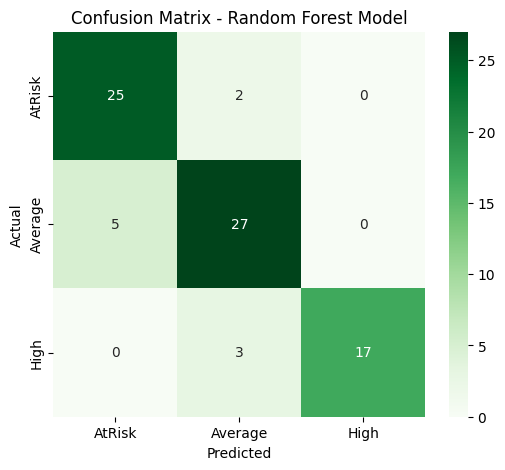

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

labels = ["AtRisk", "Average", "High"]

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=labels,
            yticklabels=labels)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Random Forest Model")
plt.show()

In [ ]:
joblib.dump(model, "student_performance_model.pkl")

['student_performance_model.pkl']

In [ ]:
%%writefile app.py
from flask import Flask, request, jsonify
import joblib
import numpy as np

app = Flask(__name__)

model = joblib.load("student_performance_model.pkl")

@app.route("/predict", methods=["POST"])
def predict():
    data = request.json

    features = np.array([[
        data["studytime"],
        data["failures"],
        data["absences"],
        data["G1"],
        data["G2"]
    ]])

    prediction = model.predict(features)[0]

    labels = ["AtRisk", "Average", "High"]

    return jsonify({"result": labels[prediction]})

if __name__ == "__main__":
    app.run()

Writing app.py


In [ ]:
%%writefile requirements.txt
flask
numpy
scikit-learn
gunicorn
joblib

Writing requirements.txt


In [ ]:
!pip install flask pyngrok

In [ ]:
from flask import Flask, request, jsonify
from pyngrok import ngrok
import numpy as np
import joblib

app = Flask(__name__)

# Load your trained Random Forest model
rf_model = joblib.load("student_performance_model.pkl")

@app.route("/predict", methods=["POST"])
def predict():
    data = request.json

    features = np.array([[
        data["studytime"],
        data["failures"],
        data["absences"],
        data["G1"],
        data["G2"]
    ]])

    prediction = rf_model.predict(features)[0]

    labels = ["AtRisk", "Average", "High"]

    return jsonify({"result": labels[prediction]})

In [ ]:
import threading

def run_flask():
    app.run(port=5000)

threading.Thread(target=run_flask).start()

ngrok.set_auth_token("39z29HpEVNM9YcnOh5OVXTMGOYt_7cGM5DHgwCeiVXgEA39ip")

public_url = ngrok.connect(5000)

print("🚀 Public URL:", public_url)
print("👉 Prediction endpoint:", str(public_url) + "/predict")

 * Serving Flask app '__main__'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on http://127.0.0.1:5000
INFO:werkzeug:Press CTRL+C to quit


🚀 Public URL: NgrokTunnel: "https://allan-nondiaphanous-inhomogeneously.ngrok-free.dev" -> "http://localhost:5000"
👉 Prediction endpoint: NgrokTunnel: "https://allan-nondiaphanous-inhomogeneously.ngrok-free.dev" -> "http://localhost:5000"/predict


In [ ]:
import requests

url = "http://localhost:5000/predict"

data = {
    "studytime": 3,
    "failures": 0,
    "absences": 4,
    "G1": 12,
    "G2": 14
}

response = requests.post(url, json=data)

print(response.status_code)
print(response.text)

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
INFO:werkzeug:127.0.0.1 - - [23/Feb/2026 08:07:22] "POST /predict HTTP/1.1" 200 -


200
{"result":"Average"}

